In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score,
                             davies_bouldin_score)

In [3]:
df=pd.read_csv("d:\\project\\14. PCA\\wine.csv")

EDA

In [5]:
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [17]:
print("the shape of the dataframe is:", df.shape)
#number of rows and columns 

the shape of the dataframe is: (178, 14)


In [ ]:
df.columns
# column names

Index(['Type', 'Alcohol', 'Malic', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols',
       'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color', 'Hue',
       'Dilution', 'Proline'],
      dtype='str')

In [18]:
df.info()
#data types and non-null values

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [19]:
df.describe()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [13]:
df.isnull().sum()

Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.nunique()

Type                 3
Alcohol            126
Malic              133
Ash                 79
Alcalinity          63
Magnesium           53
Phenols             97
Flavanoids         132
Nonflavanoids       39
Proanthocyanins    101
Color              132
Hue                 78
Dilution           122
Proline            121
dtype: int64

In [21]:
numerical_cols= df.select_dtypes(include=np.number).columns
print(numerical_cols)

Index(['Type', 'Alcohol', 'Malic', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols',
       'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color', 'Hue',
       'Dilution', 'Proline'],
      dtype='str')


In [45]:
# Separate target column
X = df.drop('Type', axis=1)

# Select numerical features
numerical_cols = X.select_dtypes(include=np.number).columns

print(numerical_cols)

Index(['Alcohol', 'Malic', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols',
       'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color', 'Hue',
       'Dilution', 'Proline'],
      dtype='str')


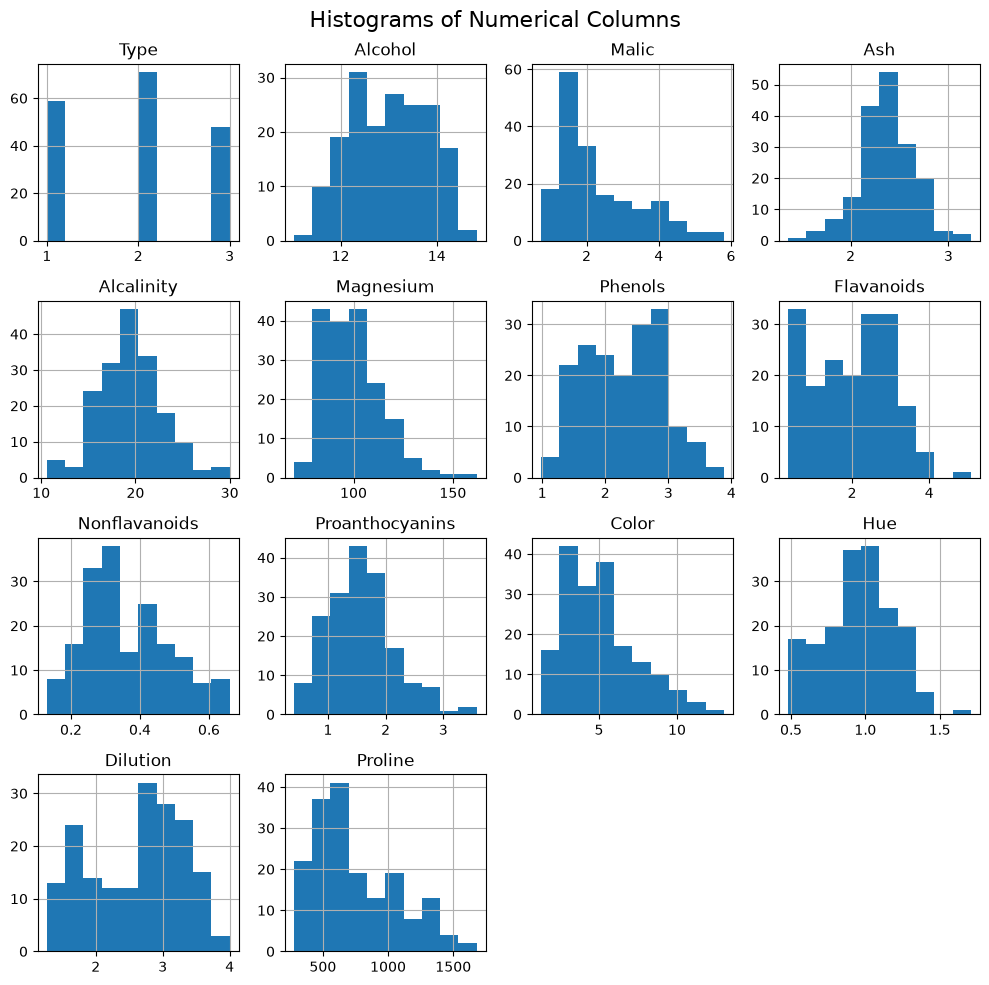

In [31]:
df[numerical_cols].hist(figsize=(10,10))

plt.suptitle("Histograms of Numerical Columns", fontsize=16)
plt.tight_layout()
plt.show()

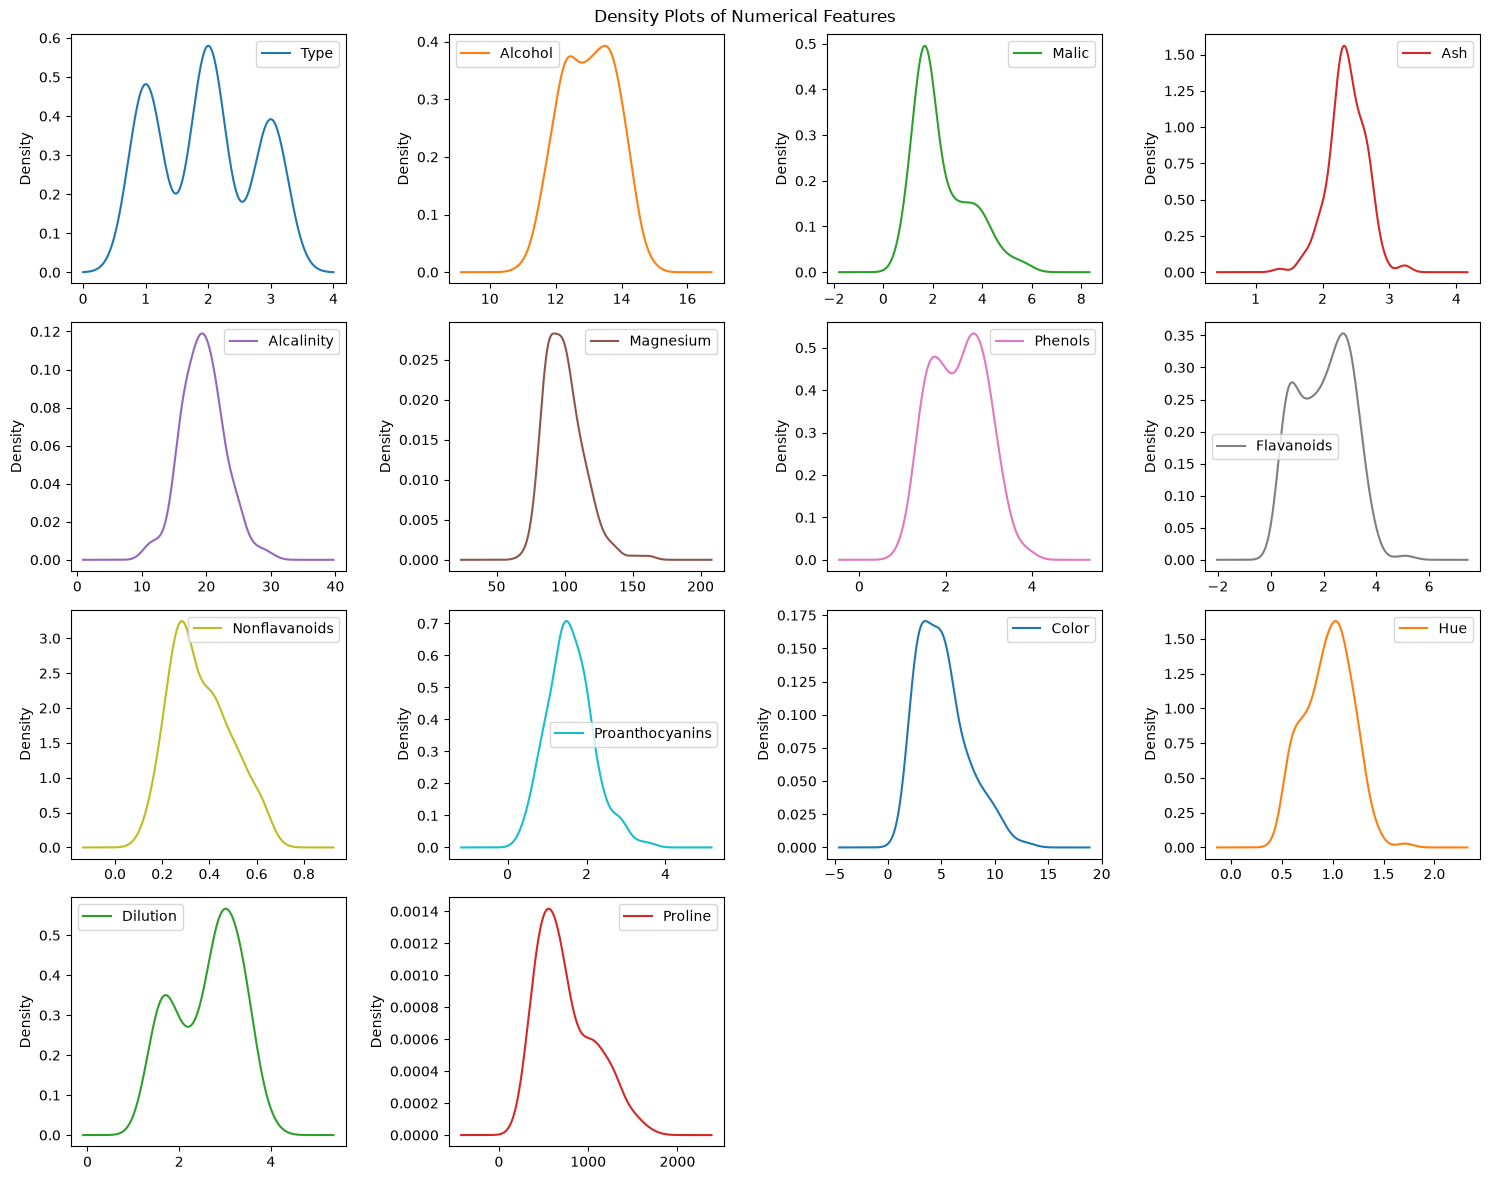

In [29]:
df[numerical_cols].plot(
    kind='density',
    subplots=True,
    layout=(4, 4),
    figsize=(15, 12),
    sharex=False
)

plt.suptitle("Density Plots of Numerical Features")
plt.tight_layout()
plt.show()

Density plots shows the smooth distribution of numerical features.

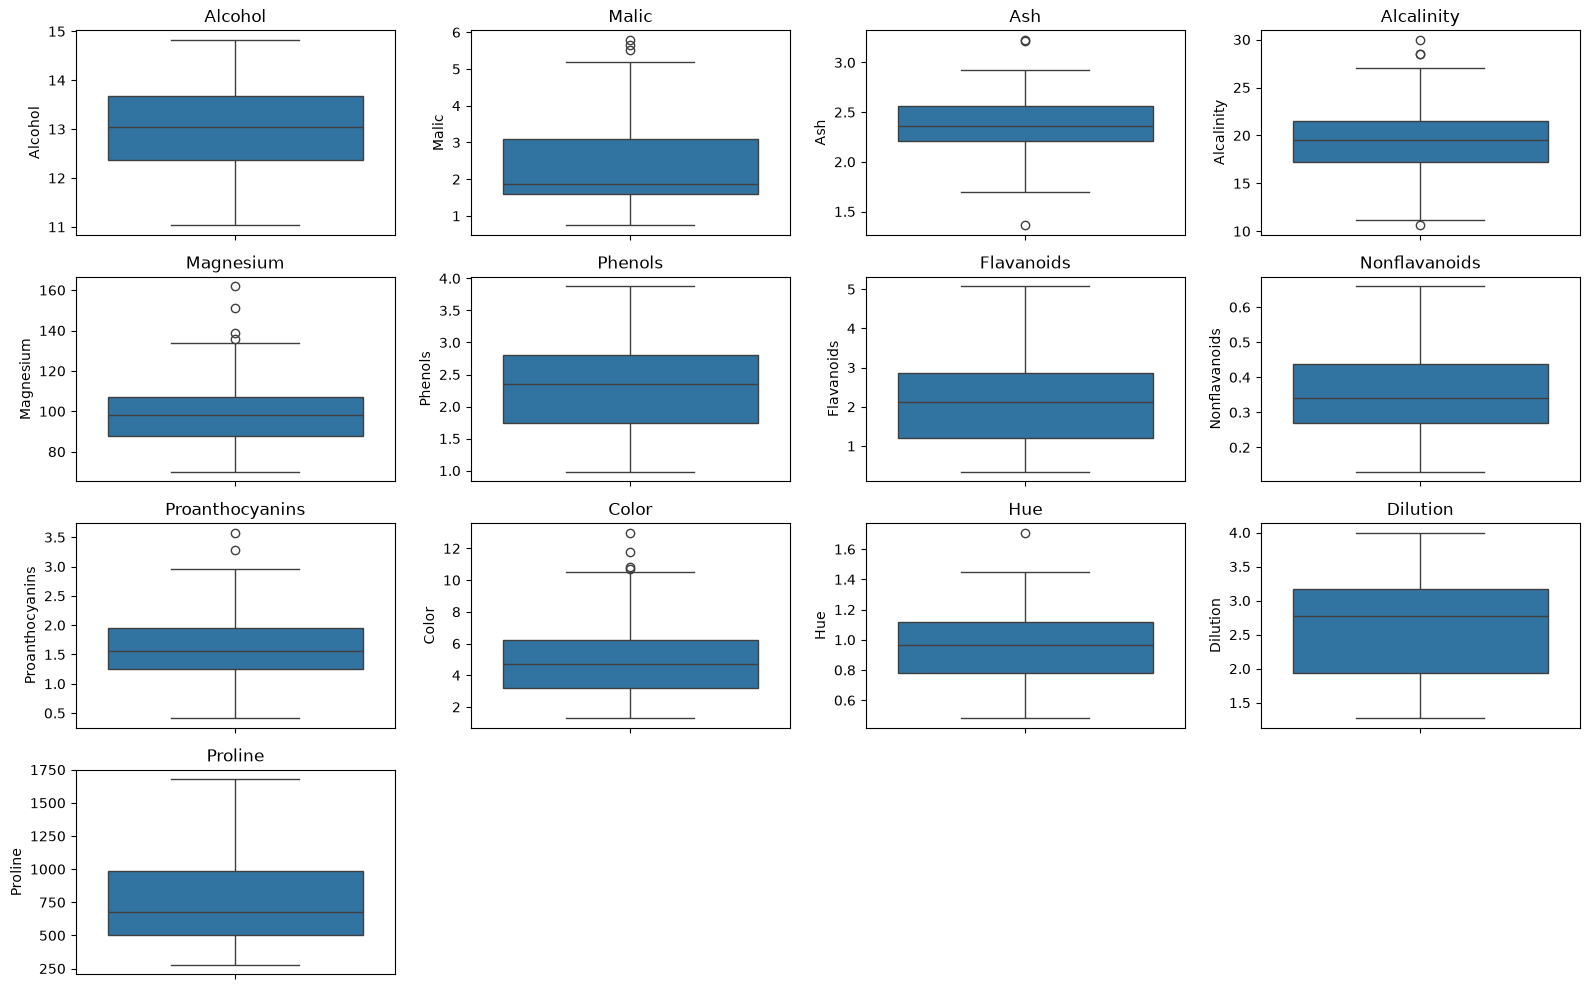

In [39]:
plt.figure(figsize=(16, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=X[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [30]:
correlation_matrix = df[numerical_cols].corr()
correlation_matrix

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
Type,1.000000,-0.328222,0.437776,-0.049643,0.517859,-0.209179,-0.719163,-0.847498,0.489109,-0.499130,0.265668,-0.617369,-0.788230,-0.633717
Alcohol,-0.328222,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
Malic,0.437776,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
Ash,-0.049643,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
Alcalinity,0.517859,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
Magnesium,-0.209179,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
Phenols,-0.719163,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
Flavanoids,-0.847498,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
Nonflavanoids,0.489109,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
Proanthocyanins,-0.499130,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417


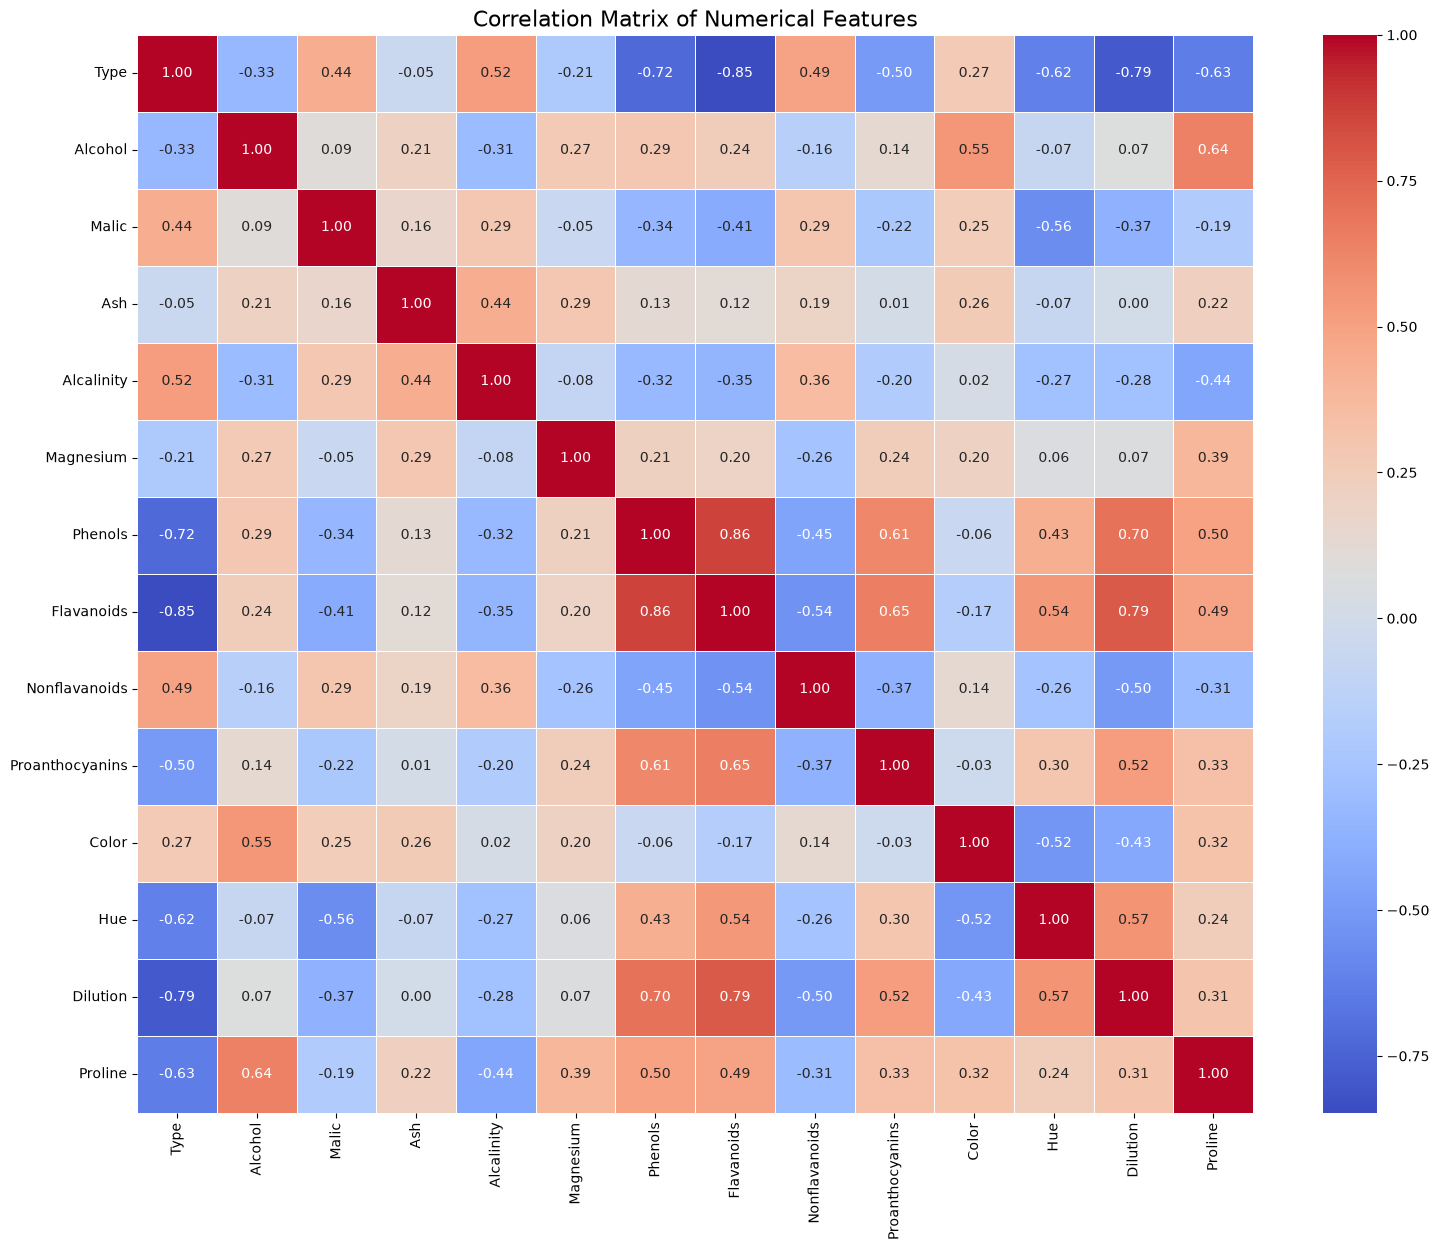

In [35]:
plt.figure(figsize=(18,14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5

)
plt.title("Correlation Matrix of Numerical Features", fontsize=16)
plt.show()

In [36]:
upper= correlation_matrix.where(
np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
#display the higher correlated feature pairs

high_corr= upper.stack().reset_index()

high_corr.columns= ['Feature 1', 'Feature 2', 'Correlation']

high_corr[high_corr['Correlation'].abs()>0.7]

,Feature 1,Feature 2,Correlation
6,Type,Phenols,-0.719163
7,Type,Flavanoids,-0.847498
12,Type,Dilution,-0.788230
91,Phenols,Flavanoids,0.864564
110,Flavanoids,Dilution,0.787194


## Feature Standardization and PCA Implementation

Before applying **PCA** it is important to standardize the numerical features. As the Wine dataset contains features with different measurement  scales. 

In [51]:
# Independent variables
X = df.drop('Type', axis=1)

# Dependent variable
y = df['Type']

In [52]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [53]:
# Check mean of standardized features
X_scaled.mean(axis=0)

array([-8.38280756e-16, -1.19754394e-16, -8.37033314e-16, -3.99181312e-17,
       -3.99181312e-17,  0.00000000e+00, -3.99181312e-16,  3.59263181e-16,
       -1.19754394e-16,  2.49488320e-17,  1.99590656e-16,  3.19345050e-16,
       -1.59672525e-16])

In [54]:
# Check standard deviation
X_scaled.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [55]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

In [56]:
# Calculate explained variance ratio
explained_variance = pca.explained_variance_ratio_

print(explained_variance)

[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]


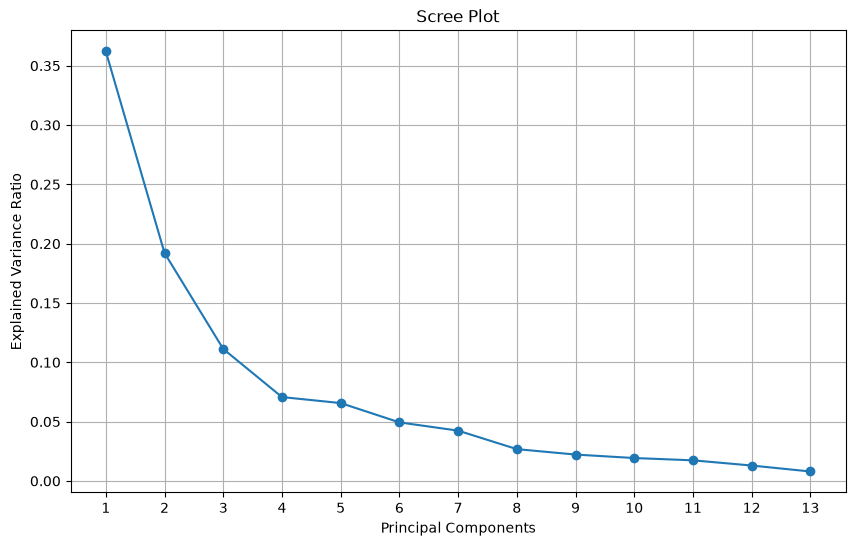

In [57]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o'
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid()
plt.show()

In [58]:
cumulative_variance = np.cumsum(explained_variance)

print(cumulative_variance)

[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


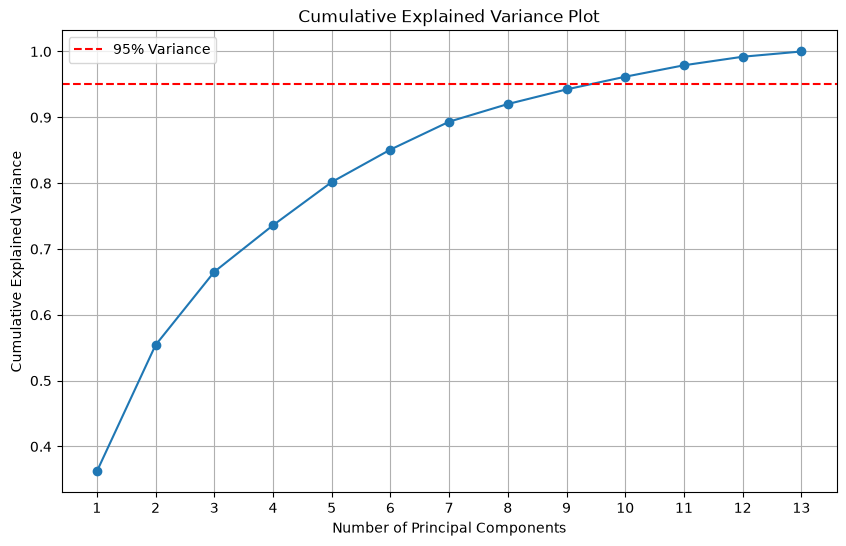

In [59]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance Plot")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid()
plt.show()

In [60]:
optimal_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Optimal number of components:", optimal_components)

Optimal number of components: 10


In [61]:
# Apply PCA using the optimal number of components
pca_final = PCA(n_components=optimal_components)

X_pca_final = pca_final.fit_transform(X_scaled)

In [62]:
# Create principal component column names
pc_columns = [
    f'PC{i+1}' for i in range(optimal_components)
]

# Convert transformed data into DataFrame
pca_df = pd.DataFrame(
    X_pca_final,
    columns=pc_columns
)

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366


In [63]:
pca_df['Type'] = y.values

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Type
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956,1
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701,1
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361,1
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413,1
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366,1


In [64]:
print("Original dataset shape:", X.shape)

print("Reduced dataset shape:", X_pca_final.shape)

Original dataset shape: (178, 13)
Reduced dataset shape: (178, 10)


In [65]:
print(
    "Total explained variance:",
    pca_final.explained_variance_ratio_.sum()
)

Total explained variance: 0.9616971684450644


In [66]:
print(
    "Percentage of variance retained:",
    pca_final.explained_variance_ratio_.sum() * 100
)

Percentage of variance retained: 96.16971684450644


In [68]:
kmeans_original = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

original_labels = kmeans_original.fit_predict(X_scaled)

In [69]:
original_df = X.copy()

original_df['Cluster'] = original_labels

original_df['Type'] = y.values

original_df.head()

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline,Cluster,Type
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,2,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,2,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,2,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,2,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,2,1


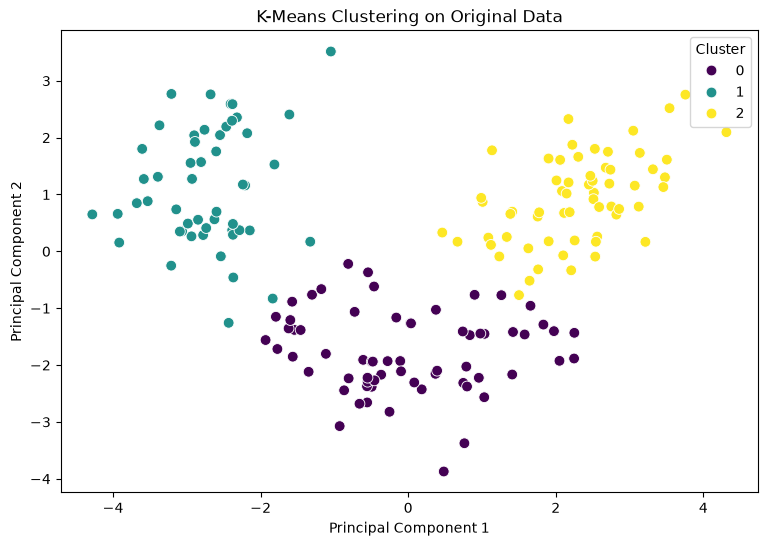

In [70]:
# Create 2D PCA projection for visualization
pca_visual = PCA(n_components=2)

X_original_2d = pca_visual.fit_transform(X_scaled)

# Plot clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_original_2d[:, 0],
    y=X_original_2d[:, 1],
    hue=original_labels,
    palette='viridis',
    s=60
)

plt.title("K-Means Clustering on Original Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

In [71]:
sil_original = silhouette_score(
    X_scaled,
    original_labels
)

print("Original Data Silhouette Score:", sil_original)

Original Data Silhouette Score: 0.2848589191898987


In [72]:
db_original = davies_bouldin_score(
    X_scaled,
    original_labels
)

print("Original Data Davies-Bouldin Index:", db_original)

Original Data Davies-Bouldin Index: 1.3891879777181648


In [73]:
kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

pca_labels = kmeans_pca.fit_predict(X_pca_final)

In [74]:
pca_cluster_df = pd.DataFrame(
    X_pca_final,
    columns=pc_columns
)

pca_cluster_df['Cluster'] = pca_labels

pca_cluster_df['Type'] = y.values

pca_cluster_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Cluster,Type
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956,2,1
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701,2,1
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361,2,1
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413,2,1
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366,2,1


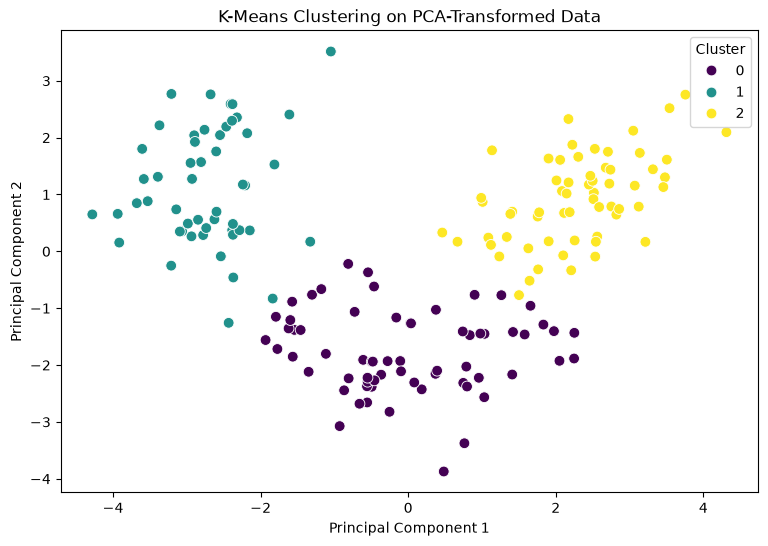

In [75]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=pca_labels,
    palette='viridis',
    s=60
)

plt.title("K-Means Clustering on PCA-Transformed Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

In [76]:
sil_pca = silhouette_score(
    X_pca_final,
    pca_labels
)

print("PCA Data Silhouette Score:", sil_pca)

PCA Data Silhouette Score: 0.29867482943692886


In [77]:
db_pca = davies_bouldin_score(
    X_pca_final,
    pca_labels
)

print("PCA Data Davies-Bouldin Index:", db_pca)

PCA Data Davies-Bouldin Index: 1.3363263335155768


In [78]:
comparison = pd.DataFrame({
    'Method': ['Original Data', 'PCA Data'],

    'Number of Features': [
        X_scaled.shape[1],
        X_pca_final.shape[1]
    ],

    'Silhouette Score': [
        sil_original,
        sil_pca
    ],

    'Davies-Bouldin Index': [
        db_original,
        db_pca
    ]
})

comparison

,Method,Number of Features,Silhouette Score,Davies-Bouldin Index
0,Original Data,13,0.284859,1.389188
1,PCA Data,10,0.298675,1.336326


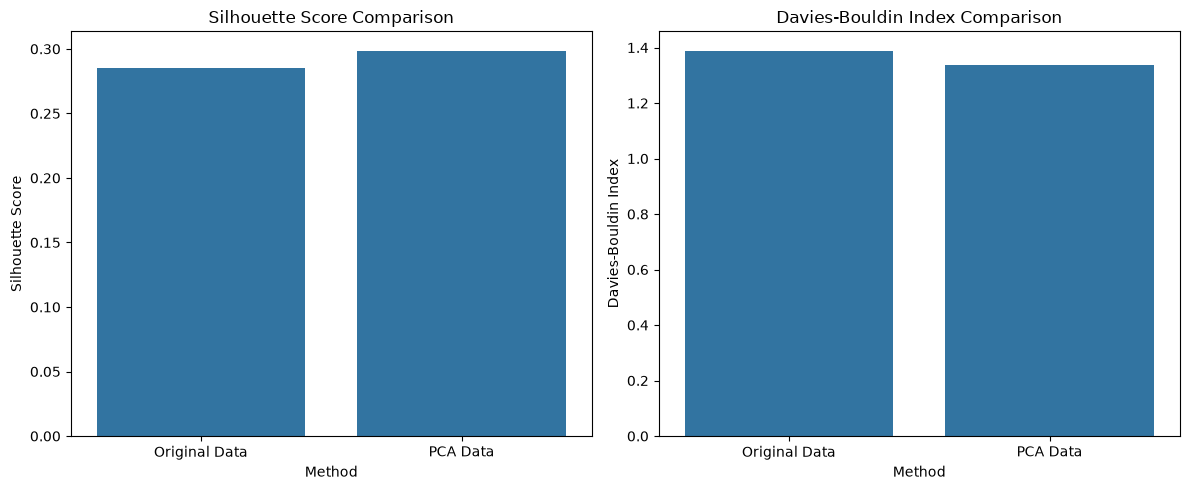

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=comparison,
    x='Method',
    y='Silhouette Score',
    ax=axes[0]
)

axes[0].set_title("Silhouette Score Comparison")

sns.barplot(
    data=comparison,
    x='Method',
    y='Davies-Bouldin Index',
    ax=axes[1]
)

axes[1].set_title("Davies-Bouldin Index Comparison")

plt.tight_layout()
plt.show()

In [80]:
pd.crosstab(
    y,
    original_labels,
    rownames=['Actual Type'],
    colnames=['Original Cluster']
)

Original Cluster,0,1,2
Actual Type,,,
1,0,0,59
2,65,3,3
3,0,48,0


In [81]:
pd.crosstab(
    y,
    pca_labels,
    rownames=['Actual Type'],
    colnames=['PCA Cluster']
)

PCA Cluster,0,1,2
Actual Type,,,
1,0,0,59
2,65,3,3
3,0,48,0


In [82]:
from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    original_labels,
    pca_labels
)

print("Adjusted Rand Index:", ari_score)


Adjusted Rand Index: 1.0


In [83]:
ari_original_type = adjusted_rand_score(y, original_labels)

ari_pca_type = adjusted_rand_score(y, pca_labels)

print("Original Data vs Actual Type:", ari_original_type)
print("PCA Data vs Actual Type:", ari_pca_type)

Original Data vs Actual Type: 0.8974949815093207
PCA Data vs Actual Type: 0.8974949815093207


## Summary

The wine dataset contains 178 observations, 13 numeircal chemical features adn one target column.


**Implications of PCA and Clustering**

Reduces the number of dimensions by combinig information from correlated features, makes high-dimensional dataset easire to visualize and process.

PCA reduced the 13 numeircal features to 10 principal components while retaining approximately 96.17% of the variance K-means was applied to both representation and evaluated using the Silhoutte Score and Davies- Bouldin Index.